# Experimento 02 - Análise Temática de Diálogos

#### Análise temática de textos em ambientes muito controlados

In [1]:
#pip install -r requirements.txt2

In [53]:
from langchain_openai import AzureChatOpenAI
from langchain_openai.embeddings import AzureOpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from tqdm import tqdm
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader

### 1 - Jogo de palavras entre os duas pessoas

##### Aqui a ideia é gerar um prompt que pede um um "jogo de palavras". Cada pessoa tem um tema, e ela diz uma palavra relacionada. Dessa forma, é criado um ambiente com temas muito controlados.

##### 1.1 - Criando o prompt 

In [145]:
load_dotenv()

llm = AzureChatOpenAI(
    model="gpt-4o", 
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

system_prompt = """
Você é um assistente inteligente que vai construir uma conversa entre duas pessoas sobre um tema, o {topico_1}. É uma conversa contínua que gira em torno apenas desse tema,
não existe nenhum tipo de transição temática.

Siga o seguinte padrão para a conversa:

Persona 1: [fala algo que pode ser relacionado a {topico_1}]
Persona 2: [responde, ainda relacionado a {topico_1}]
... 


---------------

Continue a conversa por pelo menos 150 trocas de mensagens
"""


prompt = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt),
            ("human", "Gere a conversa entre as duas personas."),
        ]
)

chain = prompt | llm | StrOutputParser()

In [146]:
response = chain.invoke({
    "topico_1": "animais"
})

In [147]:
response

'Persona 1: Eu estava lendo sobre tigres hoje, sabia que eles são os maiores felinos do mundo?  \nPersona 2: Sim, é incrível! E a força deles também é impressionante. Você sabia que eles podem arrastar presas pesando mais de 500 kg?  \n\nPersona 1: Uau, isso é fascinante. E você sabia que tigres têm padrões únicos nas listras, como uma impressão digital?  \nPersona 2: Sabia! É uma das formas de identificá-los na natureza. Os pesquisadores tiram fotos e comparam o padrão para monitorar cada um deles.  \n\nPersona 1: Isso é muito interessante. Também fiquei sabendo que os elefantes conseguem reconhecer suas próprias imagens em um espelho.  \nPersona 2: Verdade, eles são extremamente inteligentes. Aliás, eles têm uma memória impressionante! Não é à toa que falam sobre a "memória de elefante".  \n\nPersona 1: E eles também são muito sociais, né? Os elefantes criam laços com seu grupo e até demonstram tristeza quando algum membro morre.  \nPersona 2: Sim, dá pra perceber o quanto eles são e

In [148]:
def pessoa (message: str) -> str:
    if message.startswith("Persona 1:"):
        return "Persona 1"
    elif message.startswith("Persona 2:"):
        return "Persona 2"
    else:
        return "Unknown"

conversa = response.split("\n")
conversa = [line for line in conversa if line.strip() != ""]
conversation_lista = [{"persona": pessoa (line), "mensagem": line[11:]} for line in conversa]

print(conversation_lista[:10])

[{'persona': 'Persona 1', 'mensagem': 'Eu estava lendo sobre tigres hoje, sabia que eles são os maiores felinos do mundo?  '}, {'persona': 'Persona 2', 'mensagem': 'Sim, é incrível! E a força deles também é impressionante. Você sabia que eles podem arrastar presas pesando mais de 500 kg?  '}, {'persona': 'Persona 1', 'mensagem': 'Uau, isso é fascinante. E você sabia que tigres têm padrões únicos nas listras, como uma impressão digital?  '}, {'persona': 'Persona 2', 'mensagem': 'Sabia! É uma das formas de identificá-los na natureza. Os pesquisadores tiram fotos e comparam o padrão para monitorar cada um deles.  '}, {'persona': 'Persona 1', 'mensagem': 'Isso é muito interessante. Também fiquei sabendo que os elefantes conseguem reconhecer suas próprias imagens em um espelho.  '}, {'persona': 'Persona 2', 'mensagem': 'Verdade, eles são extremamente inteligentes. Aliás, eles têm uma memória impressionante! Não é à toa que falam sobre a "memória de elefante".  '}, {'persona': 'Persona 1', '

In [149]:
len(conversa), len(conversation_lista)

(88, 88)

In [150]:
all_data_list = []
for i in range(len(conversa)):
    all_data_list.append({
        "persona": conversation_lista[i]["persona"],
        "mensagem": conversation_lista[i]["mensagem"]
    })

In [151]:
with open("data_json/conversation_data.json", "w", encoding="utf-8") as f:
    json.dump(all_data_list, f, ensure_ascii=False, indent=4)

In [152]:
with open("data_json/conversation_data.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   
    print(loaded_content[:5])

[{'persona': 'Persona 1', 'mensagem': 'Eu estava lendo sobre tigres hoje, sabia que eles são os maiores felinos do mundo?  '}, {'persona': 'Persona 2', 'mensagem': 'Sim, é incrível! E a força deles também é impressionante. Você sabia que eles podem arrastar presas pesando mais de 500 kg?  '}, {'persona': 'Persona 1', 'mensagem': 'Uau, isso é fascinante. E você sabia que tigres têm padrões únicos nas listras, como uma impressão digital?  '}, {'persona': 'Persona 2', 'mensagem': 'Sabia! É uma das formas de identificá-los na natureza. Os pesquisadores tiram fotos e comparam o padrão para monitorar cada um deles.  '}, {'persona': 'Persona 1', 'mensagem': 'Isso é muito interessante. Também fiquei sabendo que os elefantes conseguem reconhecer suas próprias imagens em um espelho.  '}]


In [153]:
loaded_content[:5]

[{'persona': 'Persona 1',
  'mensagem': 'Eu estava lendo sobre tigres hoje, sabia que eles são os maiores felinos do mundo?  '},
 {'persona': 'Persona 2',
  'mensagem': 'Sim, é incrível! E a força deles também é impressionante. Você sabia que eles podem arrastar presas pesando mais de 500 kg?  '},
 {'persona': 'Persona 1',
  'mensagem': 'Uau, isso é fascinante. E você sabia que tigres têm padrões únicos nas listras, como uma impressão digital?  '},
 {'persona': 'Persona 2',
  'mensagem': 'Sabia! É uma das formas de identificá-los na natureza. Os pesquisadores tiram fotos e comparam o padrão para monitorar cada um deles.  '},
 {'persona': 'Persona 1',
  'mensagem': 'Isso é muito interessante. Também fiquei sabendo que os elefantes conseguem reconhecer suas próprias imagens em um espelho.  '}]

##### 1.2 - Embeddings

In [154]:
file_path_animais = "pdfs/revista_animais_continua.pdf"
loader_animais = PyPDFLoader(file_path_animais)
pages_animais = loader_animais.load()

print(f"{len(pages_animais)} páginas")

14 páginas


In [104]:
file_path_esportes = "pdfs/revista_esportes_continua.pdf"
loader_esportes = PyPDFLoader(file_path_esportes)
pages_esportes = loader_esportes.load()

print(f"{len(pages_esportes)} páginas")

18 páginas


In [155]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50,
    length_function=len,
    is_separator_regex=False,
)

In [156]:
chunks_esportes = text_splitter.split_documents(pages_esportes)
print(f"{len(chunks_esportes)} chunks")

chunks_animais = text_splitter.split_documents(pages_animais)
print(f"{len(chunks_animais)} chunks")

125 chunks
96 chunks


In [157]:
with open("data_json/conversation_data.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   

In [158]:
chunks = []
for item in loaded_content:
    chunks.append(item["mensagem"])

print(len(chunks))

88


In [159]:
embeddings = AzureOpenAIEmbeddings(
    model ="text-embedding-3-small",
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

vectors_conversations = np.array(embeddings.embed_documents([chunk for chunk in chunks]))
vector_animais = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_animais]))
vector_esportes = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_esportes]))
all_vectors = np.concatenate([vectors_conversations, vector_animais, vector_esportes], axis=0)
all_vectors.shape

(309, 1536)

In [178]:
tsne = TSNE(n_components=2, random_state=42, perplexity = 25)
vectors_tsne = tsne.fit_transform(all_vectors)


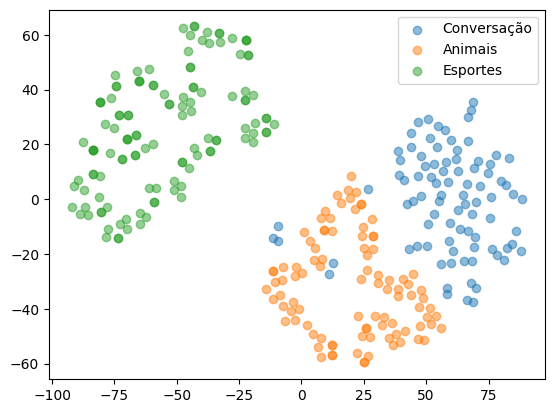

In [180]:
plt.scatter(vectors_tsne[:len(vectors_conversations), 0], vectors_tsne[:len(vectors_conversations), 1], label="Conversação", alpha=0.5)
plt.scatter(vectors_tsne[len(vectors_conversations):len(vector_animais) + len(vectors_conversations), 0], vectors_tsne[len(vectors_conversations):len(vector_animais) + len(vectors_conversations), 1], label="Animais", alpha=0.5)
plt.scatter(vectors_tsne[len(vector_animais) + len(vectors_conversations):, 0], vectors_tsne[len(vector_animais) + len(vectors_conversations):, 1], label="Esportes", alpha=0.5)
plt.legend()
plt.show()